# Data Science Tool Mastery
## Exploratory Data Analysis and Visualization

### Objective
Practice Python data science tools through data inspection,
cleaning, statistical analysis and visualization.

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Dataset
Seaborn's built-in restaurant tips dataset.
The data is used for educational analysis of bills, tips,
party size, meal times and days.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
CHART_DIR = RESULTS_DIR / "charts"

df = pd.read_csv(DATA_DIR / "restaurant_tips.csv")

print("Dataset shape:", df.shape)
print("Libraries imported successfully.")

Dataset shape: (244, 7)
Libraries imported successfully.


In [2]:
display(df.head())
display(df.dtypes.to_frame("Data Type"))
display(df.describe().round(2))

print("Missing values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("Duplicate rows:", df.duplicated().sum())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


,Data Type
total_bill,float64
tip,float64
sex,str
smoker,str
day,str
time,str
size,int64


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


Missing values:


,Missing Count
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


Duplicate rows: 1


In [3]:
clean_df = pd.read_csv(DATA_DIR / "restaurant_tips_cleaned.csv")

clean_df["tip_percentage"] = (
    clean_df["tip"] / clean_df["total_bill"] * 100
)

print("Cleaned dataset shape:", clean_df.shape)
display(clean_df.head())
display(clean_df[["total_bill", "tip", "tip_percentage"]].describe().round(2))

Cleaned dataset shape: (243, 8)


,total_bill,tip,sex,smoker,day,time,size,tip_percentage
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


,total_bill,tip,tip_percentage
count,243.00,243.00,243.00
mean,19.81,3.00,16.08
std,8.91,1.39,6.12
min,3.07,1.00,3.56
25%,13.38,2.00,12.88
50%,17.81,2.92,15.52
75%,24.17,3.58,19.17
max,50.81,10.00,71.03


In [4]:
day_summary = (
    clean_df.groupby("day", observed=False)["tip"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(day_summary)

,count,mean,median
day,,,
Fri,19,2.73,3.00
Sat,87,2.99,2.75
Sun,76,3.26,3.15
Thur,61,2.78,2.31


average_tip_by_day.png


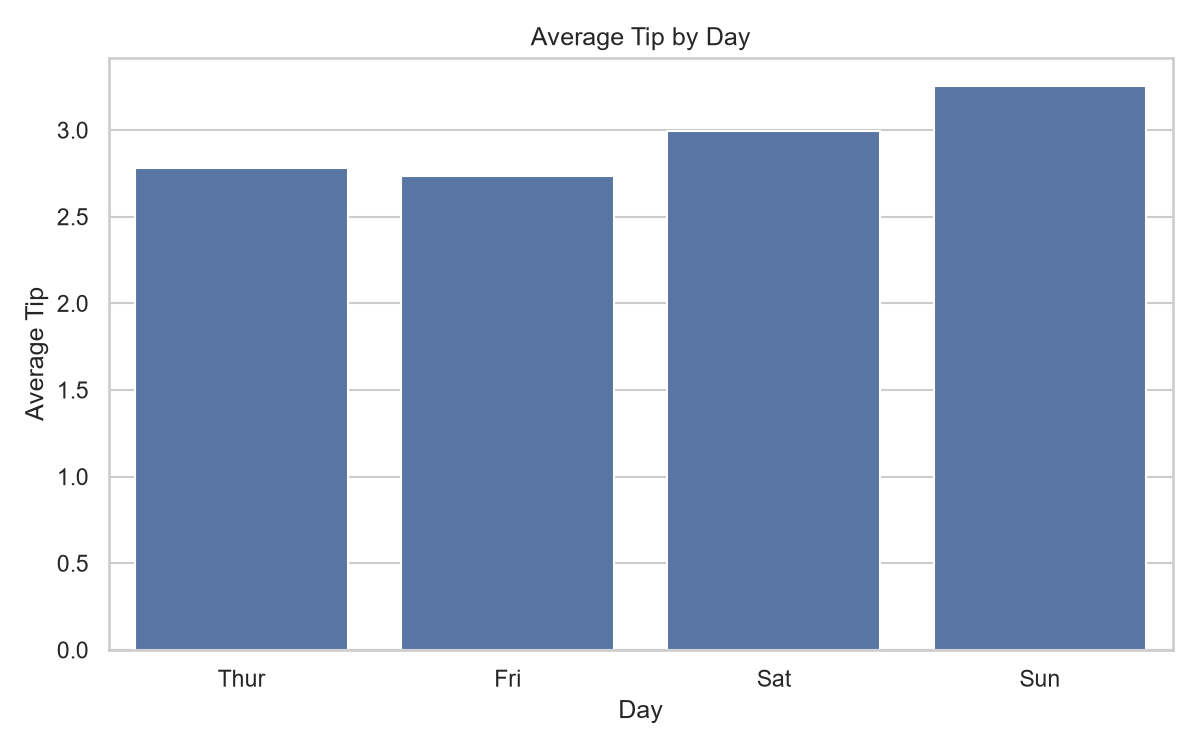

bill_distribution.png


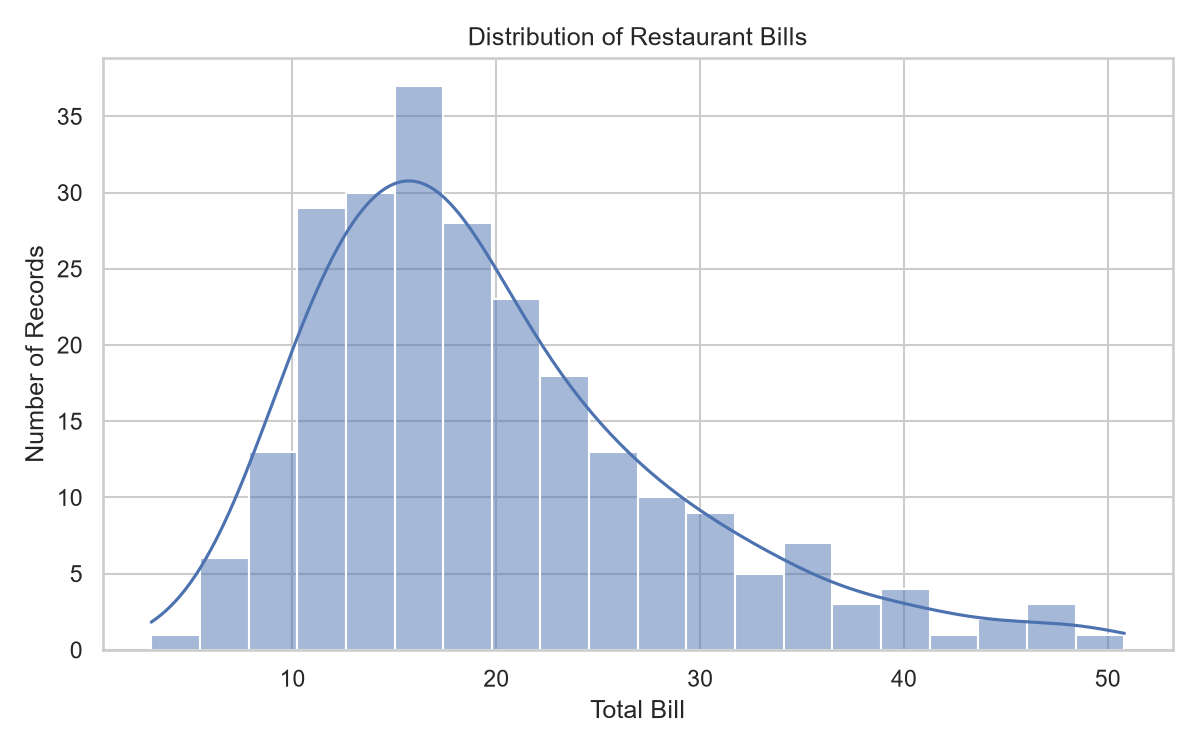

bill_vs_tip.png


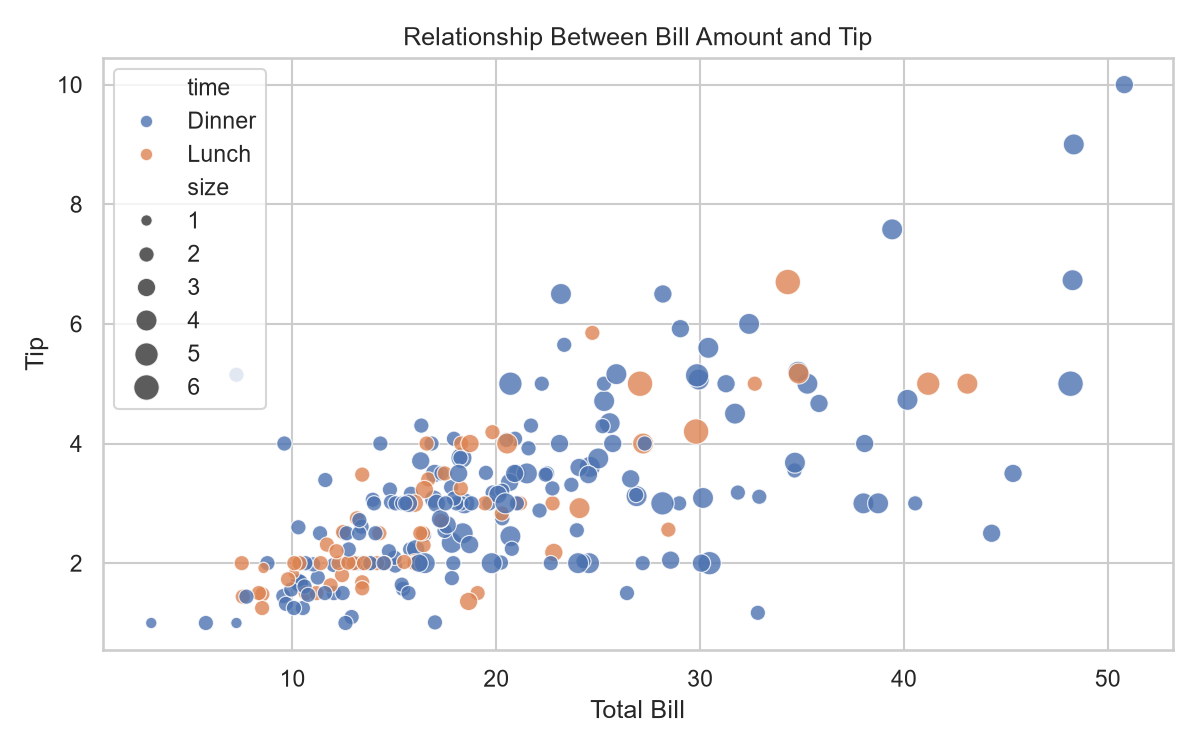

correlation_heatmap.png


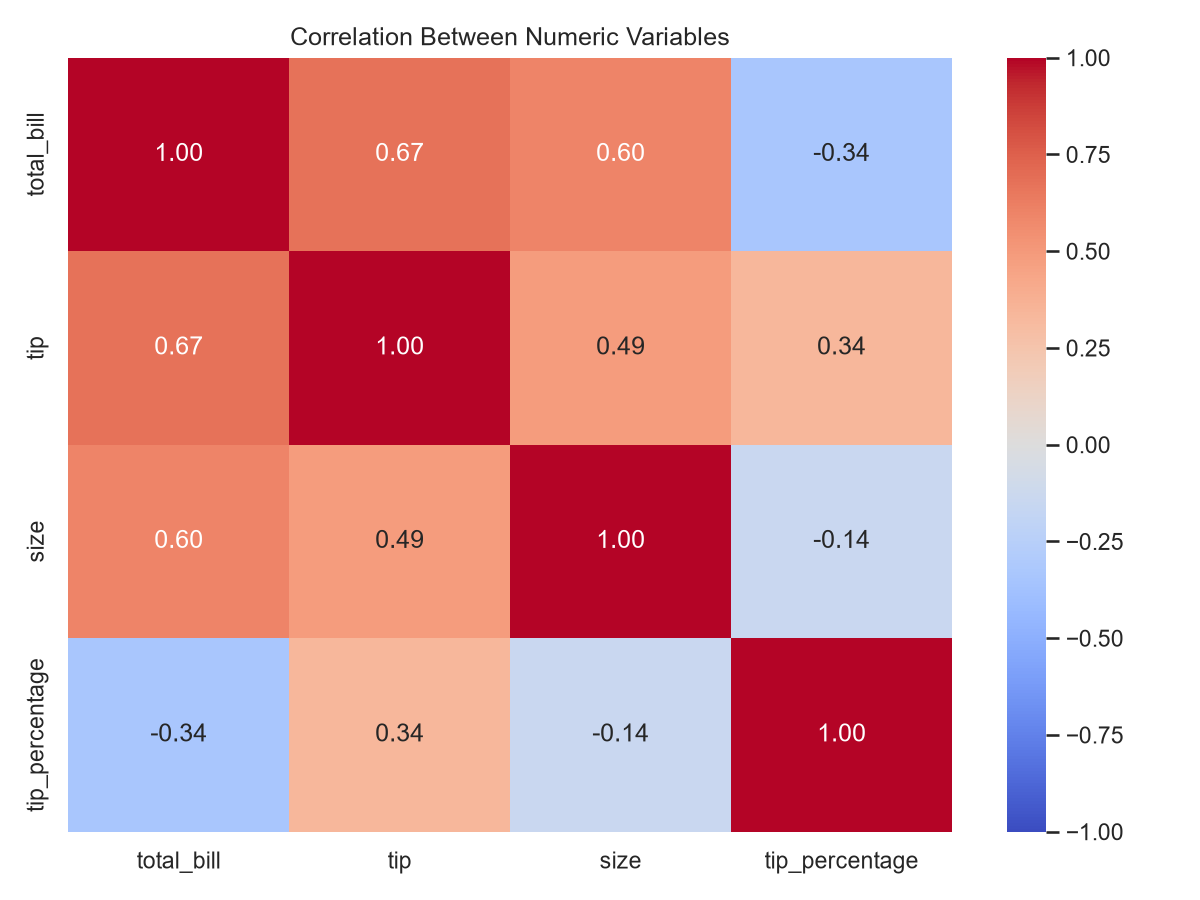

tip_percentage_by_time.png


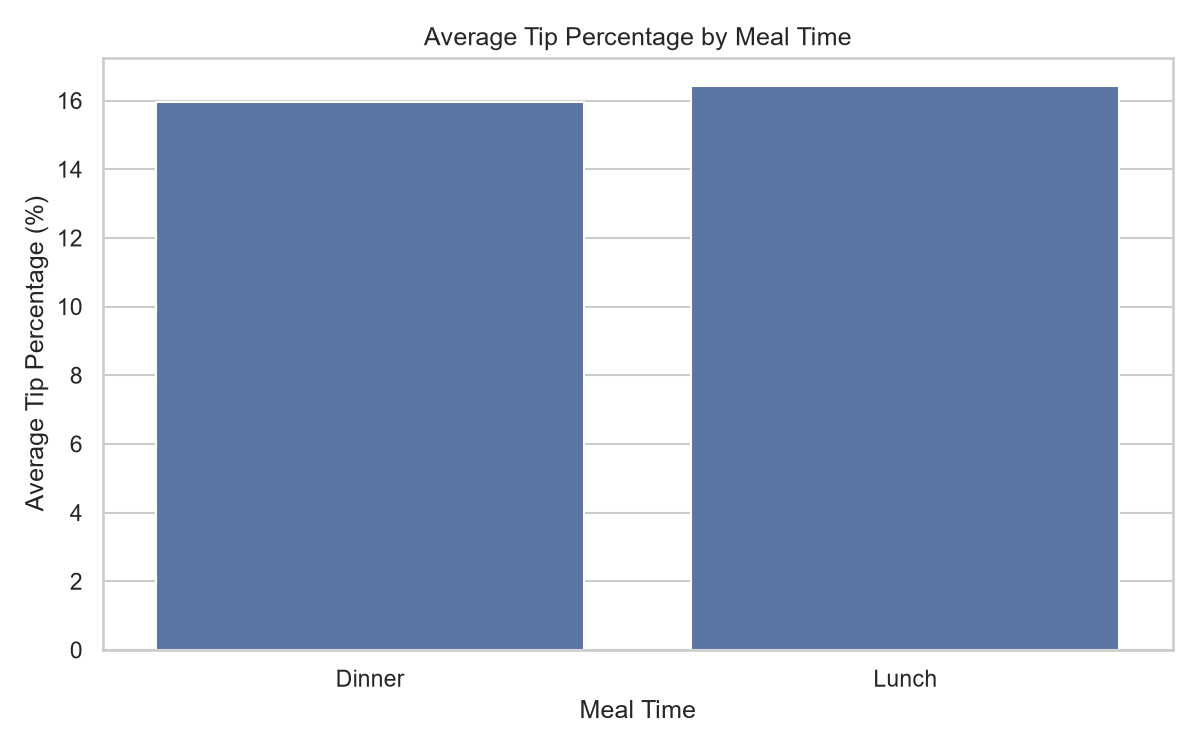

In [5]:
from IPython.display import display, Image

for chart in sorted(CHART_DIR.glob("*.png")):
    print(chart.name)
    display(Image(filename=str(chart)))

## Initial Findings

- The original dataset contains 244 records and 7 columns.
- One exact duplicate row was identified and removed.
- No missing values were found in the original dataset.
- The cleaned dataset contains 243 records.
- Sunday has the highest average tip among the four recorded days.

## Limitations

- This is a small educational dataset, not a representative sample
  of all restaurants or customers.
- Associations between bills, tips and customer characteristics
  do not prove causation.
- Unusual tip percentages should be investigated rather than
  automatically removed.